# AUC analysis from HDF5

Reads the HDF5 file made by `organize_to_hdf5` (for example `nan3.h5`), calculates the absolute AUC of each neuron's Ca and HyLight response and their ratio (`abs_auc_final_lowpass_df`), and plots it with `dotplot_auc_ratio7`.

Analysis:
- **AUC** (`compute_absolute_auc_until_zero_crossing_lowpass_hz_start`): each trace is low-pass filtered (4 Hz, 4th-order Butterworth, zero-phase). The absolute area is integrated from 1 s until the filtered trace first crosses zero after 5 s.
- **Table** (`auc_ratio_dataframe`): one row per neuron, with `AUC_ca`, `AUC_hylight` and `AUC_ratio`.
- **Statistics and plot** (`dotplot_auc_ratio7`): the control genotypes are pooled. The notebook runs a Brown–Forsythe test, a Welch ANOVA and a post hoc test of each genotype against the pooled control (Dunnett, or a corrected fallback). It returns per-genotype and pooled summary tables of the means.
- **Sanity checks** (`plot_absolute_auc_sanity_checks`): shows each trace with the interval that was integrated.

Data loading: `load_all_data_from_hdf5` reads the HDF5 file into a nested dictionary (`all_data`), grouping the flies by their `condition` metadata.

**How to use:** set `H5_FILE` in section 1, then run all cells.

In [17]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Settings

In [47]:
H5_FILE = Path("your/path/here/BAY.h5")

# Compartments included in the AUC table.
compartmentlist = ["m1", "m2", "m3", "m5", "m8", "m9", "m10", "lo1", "lo4"]

## 2. Load the data

In [48]:
def load_all_data_from_hdf5(h5_file):
    """
    Read the HDF5 file made by organize_to_hdf5 into a nested dictionary,
    grouping flies by their condition attribute:

    all_data = {
      '<condition>': {
        'folder': '<condition>',
        'series': {
          '251117_s7': {
            'frequency': <float or None>,
            'compartments': {
              'lo1': {'ca': DataFrame, 'hylight': DataFrame},   # rows = neurons, columns = time points
              ...
            }
          },
          ...
        }
      },
      ...
    }
    """
    all_data = {}
    with h5py.File(h5_file, "r") as f:
        for fly_id, fly in f.items():
            condition = fly.attrs["condition"]
            for compartment, comp in fly.items():
                folder_dict = all_data.setdefault(condition, {"folder": condition, "series": {}})
                sdict = folder_dict["series"].setdefault(
                    fly_id, {"frequency": None, "compartments": {}}
                )
                freq = float(comp.attrs.get("imaging_frequency", np.nan))
                if sdict["frequency"] is None and np.isfinite(freq):
                    sdict["frequency"] = freq

                comp_dict = sdict["compartments"].setdefault(compartment, {})
                for meas_type, dset in comp.items():
                    comp_dict[meas_type] = pd.DataFrame(dset[:])
    return all_data


def summarize_all_data(all_data):
    """Number of flies (series) and neurons per condition, compartment and sensor."""
    rows = []
    for condition, folder_dict in all_data.items():
        for series_key, sdict in folder_dict["series"].items():
            for compartment, meas in sdict["compartments"].items():
                for meas_type, df in meas.items():
                    rows.append({
                        "condition": condition,
                        "compartment": compartment,
                        "sensor": meas_type,
                        "series": series_key,
                        "n_neurons": df.shape[0],
                        "has_frequency": sdict["frequency"] is not None,
                    })
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    return (df.groupby(["condition", "compartment", "sensor"])
              .agg(n_flies=("series", "nunique"),
                   n_neurons=("n_neurons", "sum"),
                   flies_without_frequency=("has_frequency", lambda s: int((~s).sum())))
              .reset_index())


def select_genotypes(all_data, genotypes=None):
    """
    Return all_data with only the listed conditions (genotypes).
    genotypes=None returns all conditions. Names must match exactly,
    including the special minus sign in names like "−Sugar".
    """
    if genotypes is None:
        return all_data
    if isinstance(genotypes, str):
        genotypes = [genotypes]
    missing = [g for g in genotypes if g not in all_data]
    if missing:
        print(f"Not found: {missing}. Available: {list(all_data)}")
    return {g: all_data[g] for g in genotypes if g in all_data}

In [49]:
all_data = load_all_data_from_hdf5(H5_FILE)
print(summarize_all_data(all_data).to_string())

  condition compartment   sensor  n_flies  n_neurons  flies_without_frequency
0   postBAY          m9       ca        6         23                        0
1   postBAY          m9  hylight        6         23                        0
2    preBAY          m9       ca        6         26                        0
3    preBAY          m9  hylight        6         26                        0


## 3. AUC functions

In [50]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt


# ============================================================
# Absolute AUC calculation with stored diagnostic information
# ============================================================

def compute_absolute_auc_until_zero_crossing_lowpass_hz_start(
    all_data,
    zero_start_time=5.0,
    auc_integration_start=1.0,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    deadband=0.0,
    min_persist_ms=1.0,
    store_processed_traces=True,
):
    """
    Low-pass filter each trace without downsampling and calculate:

        absolute AUC = integral(abs(filtered_trace), dt)

    Integration begins at `auc_integration_start` and ends at the first
    qualifying zero crossing after `zero_start_time`.

    If no qualifying crossing is found, integration continues to the
    final sample.

    Main AUC output
    ---------------
    results[genotype]["series"][series]["compartments"]
           [compartment][measurement]

    Diagnostic output
    -----------------
    results[genotype]["series"][series]["_auc_diagnostics"]
           [compartment][measurement]

    Parameters
    ----------
    all_data : dict
        Nested data dictionary.

    zero_start_time : float, default=5.0
        Time after which zero-crossing detection begins.

    auc_integration_start : float, default=1.0
        Time at which absolute-AUC integration begins.

    lowpass_cutoff_hz : float, default=4.0
        Butterworth low-pass cutoff frequency.

    filter_order : int, default=4
        Butterworth filter order.

    deadband : float, default=0.0
        Values with absolute magnitude less than or equal to this
        threshold are treated as zero during crossing detection.

    min_persist_ms : float, default=1.0
        Minimum time for which the new sign must persist following
        a candidate zero crossing.

    store_processed_traces : bool, default=True
        Store the filtered traces used for AUC calculation.

        This must be True to use
        plot_absolute_auc_sanity_checks().
    """

    # ============================================================
    # Validate inputs
    # ============================================================

    if lowpass_cutoff_hz <= 0:
        raise ValueError(
            "lowpass_cutoff_hz must be greater than zero."
        )

    if filter_order < 1:
        raise ValueError(
            "filter_order must be at least 1."
        )

    if zero_start_time < 0:
        raise ValueError(
            "zero_start_time must be non-negative."
        )

    if auc_integration_start < 0:
        raise ValueError(
            "auc_integration_start must be non-negative."
        )

    if deadband < 0:
        raise ValueError(
            "deadband must be non-negative."
        )

    if min_persist_ms < 0:
        raise ValueError(
            "min_persist_ms must be non-negative."
        )

    # ============================================================
    # Helper: interpolate non-finite samples
    # ============================================================

    def interpolate_nans(x):
        """
        Interpolate non-finite values before filtering.
        """

        x = np.asarray(
            x,
            dtype=float,
        )

        finite = np.isfinite(x)

        if not np.any(finite):
            return x.copy()

        if np.all(finite):
            return x.copy()

        indices = np.arange(
            x.size
        )

        output = x.copy()

        output[~finite] = np.interp(
            indices[~finite],
            indices[finite],
            x[finite],
        )

        return output

    # ============================================================
    # Helper: low-pass filter
    # ============================================================

    def lowpass_filter(
        x,
        frequency,
    ):
        """
        Apply zero-phase Butterworth low-pass filtering without
        downsampling.
        """

        x = np.asarray(
            x,
            dtype=float,
        )

        n = x.size

        if n == 0:
            return x.copy()

        if frequency <= 0:
            raise ValueError(
                "Sampling frequency must be greater than zero."
            )

        nyquist = (
            float(frequency)
            / 2.0
        )

        if lowpass_cutoff_hz >= nyquist:
            raise ValueError(
                f"lowpass_cutoff_hz={lowpass_cutoff_hz} Hz "
                f"must be below Nyquist "
                f"({nyquist:.3f} Hz)."
            )

        if not np.any(
            np.isfinite(x)
        ):
            return np.full(
                n,
                np.nan,
                dtype=float,
            )

        x_filled = interpolate_nans(
            x
        )

        sos = butter(
            N=filter_order,
            Wn=lowpass_cutoff_hz,
            btype="lowpass",
            fs=float(frequency),
            output="sos",
        )

        # Approximate SciPy's default SOS padding length.
        default_padlen = 3 * (
            2 * len(sos)
            + 1
            - min(
                np.sum(
                    sos[:, 2] == 0
                ),
                np.sum(
                    sos[:, 5] == 0
                ),
            )
        )

        padlen = min(
            int(default_padlen),
            n - 1,
        )

        if n < 3 or padlen < 1:
            return x_filled.copy()

        return sosfiltfilt(
            sos,
            x_filled,
            padlen=padlen,
        )

    # ============================================================
    # Helper: classify sign
    # ============================================================

    def sign_with_deadband(
        value,
    ):
        """
        Return -1, 0, or +1 after applying the deadband.
        """

        if not np.isfinite(value):
            return 0

        if abs(value) <= deadband:
            return 0

        return int(
            np.sign(value)
        )

    # ============================================================
    # Helper: find zero crossing
    # ============================================================

    def first_zero_crossing(
        trace,
        start_idx,
        frequency,
    ):
        """
        Find the first qualifying zero crossing.

        A crossing candidate occurs when:
            1. The trace enters the zero deadband; or
            2. The trace changes directly between positive and negative.

        Returns
        -------
        crossing_idx : int
            Crossing index. If no crossing is found, the final trace
            index is returned.

        crossing_found : bool
            Whether a qualifying crossing was detected.
        """

        trace = np.asarray(
            trace,
            dtype=float,
        )

        n = trace.size

        if n == 0:
            return 0, False

        start_idx = int(
            np.clip(
                start_idx,
                0,
                n - 1,
            )
        )

        if min_persist_ms > 0:

            persist_samples = max(
                1,
                int(
                    np.ceil(
                        (
                            min_persist_ms
                            / 1000.0
                        )
                        * float(frequency)
                    )
                ),
            )

        else:
            persist_samples = 0

        # Find the first signed sample after the search start.
        initial_idx = start_idx

        previous_sign = sign_with_deadband(
            trace[initial_idx]
        )

        while (
            previous_sign == 0
            and initial_idx < n - 1
        ):
            initial_idx += 1

            previous_sign = sign_with_deadband(
                trace[initial_idx]
            )

        # Remainder of trace is zero/deadband/non-finite.
        if previous_sign == 0:
            return n - 1, False

        for i in range(
            initial_idx,
            n - 1,
        ):

            current_sign = sign_with_deadband(
                trace[i]
            )

            next_sign = sign_with_deadband(
                trace[i + 1]
            )

            # Entered the zero deadband.
            if (
                current_sign != 0
                and next_sign == 0
            ):
                candidate_idx = i + 1

            # Direct positive-to-negative or negative-to-positive
            # transition.
            elif (
                current_sign != 0
                and next_sign != 0
                and current_sign != next_sign
            ):
                candidate_idx = i + 1

            else:

                if current_sign != 0:
                    previous_sign = current_sign

                continue

            # No additional persistence requirement.
            if persist_samples <= 1:
                return candidate_idx, True

            # Move through any samples inside the deadband.
            sign_check_idx = candidate_idx

            while (
                sign_check_idx < n
                and sign_with_deadband(
                    trace[sign_check_idx]
                ) == 0
            ):
                sign_check_idx += 1

            # Trace entered the deadband and stayed there.
            if sign_check_idx >= n:
                return n - 1, False

            new_sign = sign_with_deadband(
                trace[sign_check_idx]
            )

            # The signal returned to its original sign.
            if new_sign == previous_sign:
                continue

            persistence_end = min(
                n,
                sign_check_idx
                + persist_samples,
            )

            sign_persisted = all(
                sign_with_deadband(
                    trace[k]
                ) == new_sign
                for k in range(
                    sign_check_idx,
                    persistence_end,
                )
            )

            if sign_persisted:
                return candidate_idx, True

        return n - 1, False

    # ============================================================
    # Helper: absolute-value integration
    # ============================================================

    def integrate_absolute_auc(
        values,
        times,
    ):
        """
        Calculate:

            integral(abs(values), dt)

        Positive and negative signal regions therefore both contribute
        positively.
        """

        values = np.asarray(
            values,
            dtype=float,
        )

        times = np.asarray(
            times,
            dtype=float,
        )

        finite = (
            np.isfinite(values)
            & np.isfinite(times)
        )

        if np.sum(finite) < 2:
            return np.nan

        absolute_values = np.abs(
            values[finite]
        )

        finite_times = times[
            finite
        ]

        if hasattr(
            np,
            "trapezoid",
        ):
            return float(
                np.trapezoid(
                    absolute_values,
                    x=finite_times,
                )
            )

        return float(
            np.trapz(
                absolute_values,
                x=finite_times,
            )
        )

    # ============================================================
    # Main calculation
    # ============================================================

    results = {}

    for (
        genotype,
        genotype_dict,
    ) in all_data.items():

        results[genotype] = {
            "series": {}
        }

        for (
            series_name,
            series_dict,
        ) in genotype_dict[
            "series"
        ].items():

            frequency = float(
                series_dict[
                    "frequency"
                ]
            )

            if frequency <= 0:
                raise ValueError(
                    f"Invalid frequency for "
                    f"{genotype}, {series_name}: "
                    f"{frequency}"
                )

            nyquist = (
                frequency
                / 2.0
            )

            if lowpass_cutoff_hz >= nyquist:
                raise ValueError(
                    f"For {genotype}, {series_name}, "
                    f"lowpass_cutoff_hz="
                    f"{lowpass_cutoff_hz} Hz must be "
                    f"below Nyquist "
                    f"({nyquist:.3f} Hz)."
                )

            series_result = {
                "frequency":
                    frequency,

                "effective_frequency":
                    frequency,

                "processing_method":
                    "zero-phase Butterworth low-pass",

                "auc_method":
                    "integral of absolute filtered signal",

                "auc_is_absolute":
                    True,

                "lowpass_cutoff_hz":
                    lowpass_cutoff_hz,

                "filter_order":
                    filter_order,

                "zero_start_time":
                    zero_start_time,

                "auc_integration_start":
                    auc_integration_start,

                "deadband":
                    deadband,

                "min_persist_ms":
                    min_persist_ms,

                "compartments":
                    {},

                "_auc_diagnostics":
                    {},
            }

            results[
                genotype
            ]["series"][
                series_name
            ] = series_result

            for (
                compartment,
                compartment_dict,
            ) in series_dict[
                "compartments"
            ].items():

                series_result[
                    "compartments"
                ][compartment] = {}

                series_result[
                    "_auc_diagnostics"
                ][compartment] = {}

                for (
                    measurement,
                    dataframe,
                ) in compartment_dict.items():

                    auc_values = []

                    diagnostics = {
                        "auc": [],
                        "auc_start_idx": [],
                        "auc_start_time_s": [],
                        "integration_end_idx": [],
                        "integration_end_time_s": [],
                        "zero_start_idx": [],
                        "zero_start_time_s": [],
                        "zero_crossing_found": [],
                        "zero_crossing_idx": [],
                        "zero_crossing_time_s": [],
                        "effective_frequency_hz": [],
                        "processed_traces": [],
                        "processed_time_s": [],
                    }

                    for _, row in dataframe.iterrows():

                        raw_trace = row.to_numpy(
                            dtype=float
                        )

                        filtered_trace = lowpass_filter(
                            raw_trace,
                            frequency,
                        )

                        n = filtered_trace.size

                        processed_time = (
                            np.arange(
                                n,
                                dtype=float,
                            )
                            / frequency
                        )

                        # ----------------------------------------
                        # Empty trace
                        # ----------------------------------------
                        if n == 0:

                            auc = np.nan
                            auc_start_idx = None
                            integration_end_idx = None
                            zero_start_idx = None
                            crossing_idx = None
                            crossing_found = False

                        else:

                            # ------------------------------------
                            # Zero-search start
                            # ------------------------------------
                            zero_start_idx = int(
                                np.searchsorted(
                                    processed_time,
                                    zero_start_time,
                                    side="left",
                                )
                            )

                            zero_start_idx = int(
                                np.clip(
                                    zero_start_idx,
                                    0,
                                    n - 1,
                                )
                            )

                            (
                                crossing_idx,
                                crossing_found,
                            ) = first_zero_crossing(
                                filtered_trace,
                                start_idx=
                                    zero_start_idx,
                                frequency=
                                    frequency,
                            )

                            # ------------------------------------
                            # AUC start
                            # ------------------------------------
                            auc_start_idx = int(
                                np.searchsorted(
                                    processed_time,
                                    auc_integration_start,
                                    side="left",
                                )
                            )

                            auc_start_idx = int(
                                np.clip(
                                    auc_start_idx,
                                    0,
                                    n - 1,
                                )
                            )

                            integration_end_idx = max(
                                crossing_idx,
                                auc_start_idx,
                            )

                            auc_slice = slice(
                                auc_start_idx,
                                integration_end_idx + 1,
                            )

                            # Absolute value is taken inside the
                            # integration helper.
                            auc = integrate_absolute_auc(
                                filtered_trace[
                                    auc_slice
                                ],
                                processed_time[
                                    auc_slice
                                ],
                            )

                        auc_values.append(
                            auc
                        )

                        # ----------------------------------------
                        # Save diagnostics
                        # ----------------------------------------
                        diagnostics[
                            "auc"
                        ].append(
                            auc
                        )

                        diagnostics[
                            "auc_start_idx"
                        ].append(
                            auc_start_idx
                        )

                        diagnostics[
                            "auc_start_time_s"
                        ].append(
                            (
                                processed_time[
                                    auc_start_idx
                                ]
                                if auc_start_idx
                                is not None
                                else np.nan
                            )
                        )

                        diagnostics[
                            "integration_end_idx"
                        ].append(
                            integration_end_idx
                        )

                        diagnostics[
                            "integration_end_time_s"
                        ].append(
                            (
                                processed_time[
                                    integration_end_idx
                                ]
                                if integration_end_idx
                                is not None
                                else np.nan
                            )
                        )

                        diagnostics[
                            "zero_start_idx"
                        ].append(
                            zero_start_idx
                        )

                        diagnostics[
                            "zero_start_time_s"
                        ].append(
                            (
                                processed_time[
                                    zero_start_idx
                                ]
                                if zero_start_idx
                                is not None
                                else np.nan
                            )
                        )

                        diagnostics[
                            "zero_crossing_found"
                        ].append(
                            crossing_found
                        )

                        diagnostics[
                            "zero_crossing_idx"
                        ].append(
                            (
                                crossing_idx
                                if crossing_found
                                else None
                            )
                        )

                        diagnostics[
                            "zero_crossing_time_s"
                        ].append(
                            (
                                processed_time[
                                    crossing_idx
                                ]
                                if (
                                    crossing_found
                                    and crossing_idx
                                    is not None
                                )
                                else np.nan
                            )
                        )

                        diagnostics[
                            "effective_frequency_hz"
                        ].append(
                            frequency
                        )

                        if store_processed_traces:

                            diagnostics[
                                "processed_traces"
                            ].append(
                                filtered_trace.copy()
                            )

                            diagnostics[
                                "processed_time_s"
                            ].append(
                                processed_time.copy()
                            )

                    # Main AUC output.
                    series_result[
                        "compartments"
                    ][compartment][
                        measurement
                    ] = auc_values

                    # Diagnostic output.
                    series_result[
                        "_auc_diagnostics"
                    ][compartment][
                        measurement
                    ] = diagnostics

    return results


# ============================================================
# Absolute-AUC sanity-check plotter
# ============================================================

def plot_absolute_auc_sanity_checks(
    all_data,
    auc_results,
    measurements=("ca", "hylight"),
    genotypes=None,
    series=None,
    compartments=None,
    max_plots=None,
    show_raw=True,
    show_filtered=True,
    show_zero_search_window=True,
    show_auc_start=True,
    show_zero_search_start=True,
    show_zero_crossing=True,
    figsize=None,
    raw_linewidth=0.7,
    filtered_linewidth=1.6,
    fill_alpha=0.25,
    auc_decimals=4,
    xlim=None,
    ylim=None,
    verbose=True,
):
    """
    Plot each trace and shade the exact interval used for absolute AUC.

    The plots show:
        - original trace in gray
        - low-pass-filtered trace in black
        - AUC integration start
        - zero-crossing search start
        - crossing or final endpoint
        - all positive and negative area used for absolute AUC

    Although negative regions are shown below zero, they contribute
    positively because the calculation integrates abs(filtered_trace).
    """

    # ============================================================
    # Local helper functions
    # ============================================================

    def make_filter(values):

        if values is None:
            return None

        if isinstance(
            values,
            str,
        ):
            return {values}

        return set(
            values
        )

    def passes_filter(
        value,
        allowed,
    ):

        if allowed is None:
            return True

        if value in allowed:
            return True

        return any(
            str(candidate).lower()
            == str(value).lower()
            for candidate in allowed
        )

    def normalize_name(value):

        return re.sub(
            r"[^a-z0-9]",
            "",
            str(value).lower(),
        )

    def resolve_measurements(
        available,
    ):

        available = list(
            available
        )

        if measurements is None:
            return available

        if isinstance(
            measurements,
            str,
        ):
            requested = [
                measurements
            ]

        else:
            requested = list(
                measurements
            )

        selected = []

        for request in requested:

            request_normalized = normalize_name(
                request
            )

            for candidate in available:

                candidate_normalized = normalize_name(
                    candidate
                )

                matched = (
                    candidate == request
                    or candidate_normalized
                    == request_normalized
                    or (
                        request_normalized
                        in {
                            "ca",
                            "calcium",
                        }
                        and candidate_normalized
                        in {
                            "ca",
                            "calcium",
                        }
                    )
                    or (
                        request_normalized
                        == "hylight"
                        and "hylight"
                        in candidate_normalized
                    )
                )

                if matched:

                    if candidate not in selected:
                        selected.append(
                            candidate
                        )

                    break

        return selected

    def format_measurement_name(
        measurement,
    ):

        normalized = normalize_name(
            measurement
        )

        if normalized in {
            "ca",
            "calcium",
        }:
            return "Ca"

        if "hylight" in normalized:
            return "HyLight"

        if normalized in {
            "hy800",
            "reference",
        }:
            return "Hy800"

        return str(
            measurement
        )

    genotype_filter = make_filter(
        genotypes
    )

    series_filter = make_filter(
        series
    )

    compartment_filter = make_filter(
        compartments
    )

    number_plotted = 0
    number_skipped = 0

    # ============================================================
    # Loop through results
    # ============================================================

    for (
        genotype,
        genotype_result,
    ) in auc_results.items():

        if not passes_filter(
            genotype,
            genotype_filter,
        ):
            continue

        raw_series_dictionary = (
            all_data.get(
                genotype,
                {},
            ).get(
                "series",
                {},
            )
        )

        result_series_dictionary = (
            genotype_result.get(
                "series",
                {},
            )
        )

        for (
            series_id,
            series_result,
        ) in result_series_dictionary.items():

            if not passes_filter(
                series_id,
                series_filter,
            ):
                continue

            if series_id not in raw_series_dictionary:

                if verbose:
                    print(
                        "Series missing from all_data: "
                        f"{genotype}, {series_id}"
                    )

                number_skipped += 1
                continue

            diagnostic_compartments = (
                series_result.get(
                    "_auc_diagnostics"
                )
            )

            if diagnostic_compartments is None:
                raise ValueError(
                    "\nNo _auc_diagnostics were found.\n\n"
                    "Rerun:\n\n"
                    "compute_absolute_auc_until_zero_crossing_"
                    "lowpass_hz_start(\n"
                    "    all_data,\n"
                    "    store_processed_traces=True,\n"
                    ")\n"
                )

            raw_series = raw_series_dictionary[
                series_id
            ]

            frequency = float(
                raw_series[
                    "frequency"
                ]
            )

            raw_compartments = (
                raw_series.get(
                    "compartments",
                    {},
                )
            )

            for (
                compartment,
                measurement_diagnostics,
            ) in diagnostic_compartments.items():

                if not passes_filter(
                    compartment,
                    compartment_filter,
                ):
                    continue

                if compartment not in raw_compartments:

                    if verbose:
                        print(
                            "Compartment missing from all_data: "
                            f"{genotype}, {series_id}, "
                            f"{compartment}"
                        )

                    number_skipped += 1
                    continue

                selected_measurements = (
                    resolve_measurements(
                        measurement_diagnostics.keys()
                    )
                )

                if not selected_measurements:

                    if verbose:
                        print(
                            "No requested measurements found for "
                            f"{genotype}, {series_id}, "
                            f"{compartment}. Available: "
                            f"{list(measurement_diagnostics)}"
                        )

                    number_skipped += 1
                    continue

                raw_compartment = raw_compartments[
                    compartment
                ]

                number_of_traces = max(
                    len(
                        measurement_diagnostics[
                            measurement
                        ]["auc"]
                    )
                    for measurement
                    in selected_measurements
                )

                if verbose:
                    print(
                        f"\n{genotype} | "
                        f"{series_id} | "
                        f"{compartment} | "
                        f"{number_of_traces} traces"
                    )

                # ====================================================
                # One figure per neuron/trace
                # ====================================================

                for trace_index in range(
                    number_of_traces
                ):

                    if (
                        max_plots is not None
                        and number_plotted
                        >= max_plots
                    ):
                        print(
                            f"\nPlotted {number_plotted} "
                            "neuron-level absolute-AUC checks."
                        )
                        return

                    number_of_rows = len(
                        selected_measurements
                    )

                    current_figsize = (
                        figsize
                        if figsize is not None
                        else (
                            8,
                            3.2
                            * number_of_rows,
                        )
                    )

                    figure, axes = plt.subplots(
                        number_of_rows,
                        1,
                        figsize=current_figsize,
                        sharex=True,
                        squeeze=False,
                    )

                    axes = axes.ravel()

                    for (
                        axis,
                        measurement,
                    ) in zip(
                        axes,
                        selected_measurements,
                    ):

                        diagnostics = (
                            measurement_diagnostics[
                                measurement
                            ]
                        )

                        if (
                            trace_index
                            >= len(
                                diagnostics["auc"]
                            )
                        ):
                            axis.set_visible(
                                False
                            )
                            continue

                        measurement_name = (
                            format_measurement_name(
                                measurement
                            )
                        )

                        # ----------------------------------------
                        # Raw trace
                        # ----------------------------------------
                        raw_data = raw_compartment.get(
                            measurement
                        )

                        if (
                            show_raw
                            and isinstance(
                                raw_data,
                                pd.DataFrame,
                            )
                            and trace_index
                            < len(raw_data)
                        ):

                            raw_trace = raw_data.iloc[
                                trace_index
                            ].to_numpy(
                                dtype=float
                            )

                            raw_time = (
                                np.arange(
                                    raw_trace.size,
                                    dtype=float,
                                )
                                / frequency
                            )

                            axis.plot(
                                raw_time,
                                raw_trace,
                                color="0.75",
                                linewidth=
                                    raw_linewidth,
                                label=(
                                    f"Raw "
                                    f"({frequency:.2f} Hz)"
                                ),
                                zorder=1,
                            )

                        # ----------------------------------------
                        # Filtered trace
                        # ----------------------------------------
                        if (
                            trace_index
                            >= len(
                                diagnostics[
                                    "processed_traces"
                                ]
                            )
                            or trace_index
                            >= len(
                                diagnostics[
                                    "processed_time_s"
                                ]
                            )
                        ):
                            raise ValueError(
                                "\nFiltered traces were not stored.\n\n"
                                "Rerun the calculation with:\n\n"
                                "store_processed_traces=True"
                            )

                        filtered_trace = np.asarray(
                            diagnostics[
                                "processed_traces"
                            ][trace_index],
                            dtype=float,
                        )

                        processed_time = np.asarray(
                            diagnostics[
                                "processed_time_s"
                            ][trace_index],
                            dtype=float,
                        )

                        effective_frequency = float(
                            diagnostics[
                                "effective_frequency_hz"
                            ][trace_index]
                        )

                        if show_filtered:

                            axis.plot(
                                processed_time,
                                filtered_trace,
                                color="black",
                                linewidth=
                                    filtered_linewidth,
                                label=(
                                    "Low-pass-filtered trace "
                                    f"({effective_frequency:.2f} Hz)"
                                ),
                                zorder=4,
                            )

                        # ----------------------------------------
                        # Retrieve diagnostic values
                        # ----------------------------------------
                        auc_value = diagnostics[
                            "auc"
                        ][trace_index]

                        auc_start_idx = diagnostics[
                            "auc_start_idx"
                        ][trace_index]

                        integration_end_idx = diagnostics[
                            "integration_end_idx"
                        ][trace_index]

                        zero_start_time_actual = diagnostics[
                            "zero_start_time_s"
                        ][trace_index]

                        crossing_found = diagnostics[
                            "zero_crossing_found"
                        ][trace_index]

                        crossing_time = diagnostics[
                            "zero_crossing_time_s"
                        ][trace_index]

                        integration_end_time = diagnostics[
                            "integration_end_time_s"
                        ][trace_index]

                        # ----------------------------------------
                        # Zero-search region
                        # ----------------------------------------
                        if (
                            show_zero_search_window
                            and np.isfinite(
                                zero_start_time_actual
                            )
                            and processed_time.size > 0
                        ):

                            axis.axvspan(
                                zero_start_time_actual,
                                processed_time[-1],
                                color="0.5",
                                alpha=0.06,
                                linewidth=0,
                                zorder=0,
                            )

                        # ----------------------------------------
                        # Shade absolute-AUC integration region
                        # ----------------------------------------
                        valid_indices = (
                            auc_start_idx is not None
                            and integration_end_idx
                            is not None
                            and 0
                            <= auc_start_idx
                            < filtered_trace.size
                            and 0
                            <= integration_end_idx
                            < filtered_trace.size
                        )

                        if valid_indices:

                            auc_slice = slice(
                                auc_start_idx,
                                integration_end_idx + 1,
                            )

                            if np.isfinite(
                                auc_value
                            ):
                                auc_label = (
                                    "Absolute AUC = "
                                    f"{auc_value:.{auc_decimals}f}"
                                )

                            else:
                                auc_label = (
                                    "Absolute AUC = NaN"
                                )

                            axis.fill_between(
                                processed_time[
                                    auc_slice
                                ],
                                filtered_trace[
                                    auc_slice
                                ],
                                0,
                                alpha=fill_alpha,
                                label=auc_label,
                                zorder=2,
                            )

                        # ----------------------------------------
                        # AUC integration start
                        # ----------------------------------------
                        if (
                            show_auc_start
                            and auc_start_idx
                            is not None
                        ):

                            auc_start_time_actual = (
                                processed_time[
                                    auc_start_idx
                                ]
                            )

                            axis.axvline(
                                auc_start_time_actual,
                                color="0.35",
                                linestyle="--",
                                linewidth=1.2,
                                label=(
                                    "Absolute-AUC start = "
                                    f"{auc_start_time_actual:.2f} s"
                                ),
                                zorder=5,
                            )

                        # ----------------------------------------
                        # Zero-search start
                        # ----------------------------------------
                        if (
                            show_zero_search_start
                            and np.isfinite(
                                zero_start_time_actual
                            )
                        ):

                            axis.axvline(
                                zero_start_time_actual,
                                color="darkorange",
                                linestyle=":",
                                linewidth=1.4,
                                label=(
                                    "Zero search starts = "
                                    f"{zero_start_time_actual:.2f} s"
                                ),
                                zorder=5,
                            )

                        # ----------------------------------------
                        # Zero crossing or final endpoint
                        # ----------------------------------------
                        if show_zero_crossing:

                            endpoint = None

                            if (
                                crossing_found
                                and np.isfinite(
                                    crossing_time
                                )
                            ):

                                endpoint = float(
                                    crossing_time
                                )

                                endpoint_label = (
                                    "Zero crossing = "
                                    f"{endpoint:.2f} s"
                                )

                                endpoint_linestyle = "-"

                            elif np.isfinite(
                                integration_end_time
                            ):

                                endpoint = float(
                                    integration_end_time
                                )

                                endpoint_label = (
                                    "No crossing; "
                                    "integrated to end"
                                )

                                endpoint_linestyle = "--"

                            if endpoint is not None:

                                axis.axvline(
                                    endpoint,
                                    color="red",
                                    linestyle=
                                        endpoint_linestyle,
                                    linewidth=1.6,
                                    label=endpoint_label,
                                    zorder=6,
                                )

                                nearest_index = int(
                                    np.argmin(
                                        np.abs(
                                            processed_time
                                            - endpoint
                                        )
                                    )
                                )

                                axis.scatter(
                                    processed_time[
                                        nearest_index
                                    ],
                                    filtered_trace[
                                        nearest_index
                                    ],
                                    color="red",
                                    s=30,
                                    zorder=7,
                                )

                        axis.axhline(
                            0,
                            color="0.85",
                            linewidth=0.9,
                            zorder=1,
                        )

                        axis.set_ylabel(
                            f"{measurement_name}\n"
                            r"$\Delta F/F$"
                        )

                        if xlim is not None:
                            axis.set_xlim(
                                xlim
                            )

                        if ylim is not None:
                            axis.set_ylim(
                                ylim
                            )

                        axis.legend(
                            frameon=False,
                            fontsize=8,
                            loc="best",
                            labelspacing=0.65,
                        )

                    axes[-1].set_xlabel(
                        "Time (s)"
                    )

                    figure.suptitle(
                        f"{genotype} | "
                        f"{series_id} | "
                        f"{compartment} | "
                        f"trace {trace_index}",
                        fontsize=11,
                    )

                    figure.tight_layout(
                        rect=(
                            0,
                            0,
                            1,
                            0.96,
                        )
                    )

                    plt.show()
                    plt.close(
                        figure
                    )

                    number_plotted += 1

    print(
        f"\nPlotted {number_plotted} "
        "neuron-level absolute-AUC checks; "
        f"skipped {number_skipped} "
        "series/compartments."
    )

In [51]:
import numpy as np
import pandas as pd

def auc_ratio_dataframe(auc_data, compartments=compartmentlist):
    """
    Convert AUC results into a tidy long-form DataFrame with columns:
    ['Genotype','Series','Compartment','Trace','AUC_ca','AUC_hylight','AUC_ratio','Frequency_Hz']
    """

    rows = []

    for genotype, gdict in auc_data.items():
        series_map = gdict.get("series", {})

        for series_key, sdict in series_map.items():
            freq = sdict.get("frequency", None)
            comp_map = sdict.get("compartments", {})

            for comp in compartments:
                comp_dict = comp_map.get(comp, {})

                ca_list = comp_dict.get("ca", None)
                hy_list = comp_dict.get("hylight", None)

                # Skip compartments missing either measurement
                if ca_list is None or hy_list is None:
                    continue

                # Convert to arrays and match length
                ca_arr = np.array(ca_list, dtype=float)
                hy_arr = np.array(hy_list, dtype=float)
                n = min(len(ca_arr), len(hy_arr))
                if n == 0:
                    continue

                ca_arr = ca_arr[:n]
                hy_arr = hy_arr[:n]

                # Safe divide calcium/hylight
                
                # Safe divide hylight/calcium
                safe_ca = np.where(np.abs(ca_arr) < 1e-12, np.nan, ca_arr)
                ratio_arr = hy_arr / safe_ca
                ratio_arr = hy_arr / ca_arr

                # Build rows
                for i in range(n):
                    rows.append({
                        "Genotype": genotype,
                        "Series": series_key,
                        "Compartment": comp,
                        "Trace": i,
                        "AUC_ca": ca_arr[i],
                        "AUC_hylight": hy_arr[i],
                        "AUC_ratio": ratio_arr[i],
                        "Frequency_Hz": freq
                    })

    df = pd.DataFrame(rows, columns=[
        "Genotype","Series","Compartment","Trace",
        "AUC_ca","AUC_hylight","AUC_ratio","Frequency_Hz"
    ])

    return df

## 4. Statistics, genotype groups and plot function
The genotype order and group colors are set here.

In [52]:
import statsmodels.api as sm
# ============================================================
#  DOT PLOT (one compartment at a time) + BF, Welch, Dunnett/GH
#  Stars drawn directly above significant non-control clusters
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

# optional: p-value adjustment
try:
    from statsmodels.stats.multitest import multipletests
    _HAS_SM = True
except Exception:
    _HAS_SM = False

# optional: exact Dunnett via bioinfokit
try:
    from bioinfokit.analys import stat as _bio_stat
    _HAS_BIO = True
except Exception:
    _HAS_BIO = False

# optional: studentized range for Games–Howell p-values
try:
    from scipy.stats import studentized_range as _sr
    _HAS_SR = True
except Exception:
    _HAS_SR = False


def _padjust(pvals, method="holm"):
    pvals = np.asarray(pvals, dtype=float)
    if not len(pvals): return pvals
    if _HAS_SM:
        _, p_adj, _, _ = multipletests(pvals, method=method)
        return p_adj
    m = max(1, len(pvals))
    return np.minimum(1.0, pvals * m)

def _stars(p):
    return "****" if p <= 1e-4 else "***" if p <= 1e-3 else "**" if p <= 1e-2 else "*" if p <= 0.05 else ""
def _brown_forsythe(df_scope: pd.DataFrame, order: list) -> pd.DataFrame:
    groups = [
        df_scope.loc[df_scope["Genotype"] == g, "AUC_ratio"].dropna().values
        for g in order
    ]
    groups = [g for g in groups if g.size > 1]
    if len(groups) < 2:
        return pd.DataFrame({"stat": [np.nan], "p": [np.nan]})

    stat, p = stats.levene(*groups, center="median")
    return pd.DataFrame({"stat": [stat], "p": [p]})


def _welch_anova_manual(df_scope: pd.DataFrame, order: list) -> pd.DataFrame:
    # extract groups
    groups = [
        df_scope.loc[df_scope["Genotype"] == g, "AUC_ratio"].dropna().values
        for g in order
    ]
    groups = [g for g in groups if g.size > 1]

    if len(groups) < 2:
        return pd.DataFrame({"stat": [np.nan], "p": [np.nan]})

    k = len(groups)
    ni = np.array([len(g) for g in groups], dtype=float)
    mi = np.array([np.mean(g) for g in groups], dtype=float)
    vi = np.array([np.var(g, ddof=1) for g in groups], dtype=float)

    wi = ni / vi
    y_bar = np.sum(wi * mi) / np.sum(wi)

    numerator = np.sum(wi * (mi - y_bar) ** 2) / (k - 1)
    denominator = 1 + (2 * (k - 2) / (k**2 - 1)) * np.sum(((1 - wi / wi.sum())**2) / (ni - 1))

    stat = numerator / denominator
    df_num = k - 1
    df_den = (k**2 - 1) / (3 * np.sum(((1 - wi/wi.sum())**2) / (ni - 1)))

    p = 1 - stats.f.cdf(stat, df_num, df_den)

    return pd.DataFrame({"stat": [stat], "p": [p]})

def _posthoc_dunnett_or_fallback(df_scope, control="control", method_adj="holm"):
    df = df_scope.copy()

    # Only keep valid rows
    df = df[np.isfinite(df["AUC_ratio"])]

    groups = df["Genotype"].unique()
    groups = [g for g in groups if g != control]

    results = []

    control_vals = df.loc[df["Genotype"] == control, "AUC_ratio"].values

    for g in groups:
        vals = df.loc[df["Genotype"] == g, "AUC_ratio"].values
        if len(vals) > 1 and len(control_vals) > 1:
            stat, p = stats.ttest_ind(vals, control_vals, equal_var=False)
        else:
            p = np.nan

        results.append({"Group": g, "p_raw": p})

    out = pd.DataFrame(results)

    if out.empty:
        return out, "none"

    # multiple testing correction
    out["p_adj"] = sm.stats.multipletests(out["p_raw"], method=method_adj)[1]

    return out, method_adj

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D


# ============================================================
# HARDCODED ORDER
# ============================================================
_GENOTYPE_ORDER = [
    "control",
    "control-RNAi",
    "glut1-RNAi", "treh-RNAi", "glys-RNAi", "glyp-RNAi",
                   "hexa-RNAi",  "pfrx-RNAi_1","pfrx-RNAi_2","pfrx-3-RNAi", "pfk-RNAi",
                   "ald-RNAi", "gapdh3-RNAi", "pgk-RNAi_1", "pgk-RNAi_2",
                   "Eno-RNAi", "PyK-RNAi","ldh-RNAi", 
    
    "parkin-RNAi", "milt-RNAi", "miro-RNAi",
    "oga-RNAi", "ogt-RNAi", "ap2-RNAi", "chc-RNAi", "unc104-RNAi", "rbp-RNAi", "vacht-RNAi", "chat-RNAi",
    "vha100-RNAi", "vhaAC45RP-RNAi",
    "Pka-C1-RNAi",
    "CaMKII-dsRNA", "CaMKII-T287A", "CaMKII-T287D",
   "AMPKα-RNAi_1", "AMPKα-RNAi_2", "snf4a-RNAi", "alc-RNAi", "AMPKDN", "AMPKCA", "AMPK-OE",
     "lkb-RNAi", "tak1-RNAi", "mtor-RNAi","acly-RNAi"
]

HARDCODED_ORDER = {
    "m2": _GENOTYPE_ORDER,
    "m9": _GENOTYPE_ORDER,
    "lo1": _GENOTYPE_ORDER,
}


# ============================================================
# HARDCODED GROUPS
# ============================================================
HARDCODED_GROUPS = {
    "controls": [
        "control", "control-RNAi"
    ],
#    "glycolysis": [
#        "pfk-RNAi", "pfk-OE", "pfrx-RNAi_1","pfrx-RNAi_2", "treh-RNAi", "glut1-RNAi", "hexa-RNAi", "ald-RNAi",
#        "gapdh3-RNAi", "pgk-RNAi_1", "pgk-RNAi_2", "Eno-RNAi", "PyK-RNAi",
#        "ldh-RNAi", "glys-RNAi", "glyp-RNAi"
#    ],
    
    "glycolysis": ["glut1-RNAi", "treh-RNAi", "glys-RNAi", "glyp-RNAi",
                   "hexa-RNAi",  "pfrx-RNAi_1","pfrx-RNAi_2","pfrx-3-RNAi", "pfk-RNAi",
                   "ald-RNAi", "gapdh3-RNAi", "pgk-RNAi_1", "pgk-RNAi_2",
                   "Eno-RNAi", "PyK-RNAi","ldh-RNAi", 
    ],
    "mito": [
        "parkin-RNAi", "milt-RNAi", "miro-RNAi", "oga-RNAi", "ogt-RNAi"
    ],
    "trafficking_release": [
        "ap2-RNAi", "chc-RNAi", "unc104-RNAi",  "rbp-RNAi", "vacht-RNAi", "chat-RNAi", "vhaAC45RP-RNAi", "acly-RNAi"
    ],
    "v_atpase_lysosome": [
        "vha100-RNAi",
    ],
    "signaling": [
        "Pka-C1-RNAi", "CaMKII-dsRNA", "CaMKII-T287A", "CaMKII-T287D"
    ],
    "ampk_pathway": ["AMPKα-RNAi_1", "AMPKα-RNAi_2","AMPK-OE", "AMPKDN", "AMPKCA",
        "snf4a-RNAi", "alc-RNAi", "lkb-RNAi", "tak1-RNAi", "mtor-RNAi", "acly-RNAi"
    ],
}


HARDCODED_GROUP_COLORS = {
    "controls":            "#4d4d4d",  # charcoal
    "glycolysis":          "#2ca02c",  # bluish green
    "mito":                "#E69F00",  # deep blue
    "trafficking_release": "#0072B2",  # amber
    "v_atpase_lysosome":   "#C44E79",  # warm brown
    "signaling":           "#8064A2",  # muted purple
    "ampk_pathway":        "#C44E79",  # raspberry / magenta


}

#    "controls":            "#4d4d4d",  # charcoal
#    "glycolysis":          "#808080",  # bluish green
#    "ampk_pathway":        "#808080",  # raspberry / magenta
#    "signaling":           "#8064A2",  # muted purple
#    "mito":                "#E69F00",  # deep blue
#    "trafficking_release": "#0072B2",  # amber
#    "v_atpase_lysosome":   "#8064A2",  # warm brown


DEFAULT_GROUP_COLOR = "#bdbdbd"


# ============================================================
# BUILD LOOKUPS FROM THE HARDCODED GROUPS
# ============================================================
GENOTYPE_TO_GROUP = {}
for group_name, members in HARDCODED_GROUPS.items():
    for genotype in members:
        if genotype in GENOTYPE_TO_GROUP:
            raise ValueError(f"Genotype '{genotype}' appears in multiple groups.")
        GENOTYPE_TO_GROUP[genotype] = group_name

GENOTYPE_TO_COLOR = {
    genotype: HARDCODED_GROUP_COLORS.get(group_name, DEFAULT_GROUP_COLOR)
    for genotype, group_name in GENOTYPE_TO_GROUP.items()
}

In [54]:
def dotplot_auc_ratio7(
    ratio_df: pd.DataFrame,
    compartment: str,
    control_genotypes=("control", "control-RNAi"),
    order: list | None = None,
    posthoc_correction: str | None = "holm",
    alpha: float = 0.05,
    figsize=(7.5, 2.8),
    color="#ff7f0e",  # only used if use_group_colors=False
    jitter_width: float = 0.16,
    point_size: float = 20,
    seed: int = 7,
    remove_grid: bool = True,
    show_tables: bool = False,
    y_limits: tuple[float, float] = (0.0, 2.0),
    append_unlisted: bool = True,
    warn_missing: bool = True,
    use_group_colors: bool = True,
    default_group_color: str = DEFAULT_GROUP_COLOR,
    show_group_legend: bool = True,
    color_xticklabels: bool = False,
    show_reference_line: bool = True,
    reference_y: float = 1.0,
    star_y_axfrac: float = 0.86,
    star_fontsize: float = 10,
    show_n_in_xticklabels: bool = True,
    star_x_offset: float = 0.03,
    lowercase_xticklabels: bool = True,
    italicize_xticklabels: bool = True,
):
    """
    Dotplot for AUC_ratio, with pooled controls for statistics.
 
    Significance stars are plotted at a fixed vertical position in axis
    coordinates, which keeps them aligned even when rotated 90 degrees.
 
    Returns a dict that includes two summary tables of the means:
      "summary"        - one row per genotype, in x-axis order, with the
                         post hoc p-value attached.
      "summary_pooled" - the same statistics but with the control
                         genotypes merged into a single pooled_control
                         row, matching what the tests compared against.
    """
 
    # ----------- sanitize control list -----------
    if isinstance(control_genotypes, str):
        control_genotypes = (control_genotypes,)
    control_genotypes = tuple(str(g).strip() for g in control_genotypes)
 
    if len(control_genotypes) == 0:
        raise ValueError("control_genotypes must contain at least one genotype.")
 
    # ----------- clean dataframe -----------
    df = ratio_df.copy()
    df["Genotype"] = df["Genotype"].astype(str).str.strip()
    df["Compartment"] = df["Compartment"].astype(str).str.strip()
 
    df = df[(df["Compartment"] == compartment) & np.isfinite(df["AUC_ratio"])].copy()
    if df.empty:
        raise ValueError(f"No finite AUC_ratio data for compartment '{compartment}'.")
 
    present = df["Genotype"].unique().tolist()
 
    controls_present = [g for g in control_genotypes if g in present]
    missing_controls = [g for g in control_genotypes if g not in present]
 
    if len(controls_present) == 0:
        raise ValueError(
            f"None of the requested control_genotypes are present in the filtered data. "
            f"Requested: {control_genotypes}"
        )
 
    if warn_missing and missing_controls:
        print(f"⚠️ Control genotype(s) missing in data: {', '.join(missing_controls)}")
 
    # -------- ORDER LOGIC ----------
    if order is not None:
        desired = [str(g).strip() for g in order]
    else:
        desired = HARDCODED_ORDER.get(compartment, None)
 
    if desired:
        missing = [g for g in desired if g not in present]
        if warn_missing and missing:
            print(f"⚠️ Missing in data (ignored): {', '.join(missing)}")
 
        base = [g for g in desired if g in present]
 
        if append_unlisted:
            extras = sorted([g for g in present if g not in base])
            order = base + extras
        else:
            order = base
    else:
        non_controls = sorted([g for g in present if g not in control_genotypes])
        order = controls_present + non_controls
 
    controls_not_in_order = [g for g in controls_present if g not in order]
    if controls_not_in_order:
        order = controls_not_in_order + order
 
    # ============================================================
    # Convert selected metric to numeric
    # ============================================================
 
    metric_col = "AUC_ratio"
    df[metric_col] = pd.to_numeric(
        df[metric_col],
        errors="coerce",
    )
 
    df = df[
        np.isfinite(df[metric_col])
    ].copy()
 
    if df.empty:
 
        measurement_text = (
            f", measurement '{measurement_type}'"
            if measurement_type is not None
            else ""
        )
 
        raise ValueError(
            f"No finite '{metric_col}' data for compartment "
            f"'{compartment}'{measurement_text}."
        )
 
    # ----------- pooled-control stats dataframe -----------
    pooled_control_label = "pooled_control"
 
    df_stats = df.copy()
    df_stats["Genotype"] = df_stats["Genotype"].where(
        ~df_stats["Genotype"].isin(control_genotypes),
        pooled_control_label
    )
 
    stats_order = [pooled_control_label] + [g for g in order if g not in control_genotypes]
 
    seen = set()
    stats_order = [g for g in stats_order if not (g in seen or seen.add(g))]
 
    # ----------- Statistics -----------
    bf = _brown_forsythe(df_stats, stats_order)
    wa = _welch_anova_manual(df_stats, stats_order)
    post, method_used = _posthoc_dunnett_or_fallback(
        df_stats,
        control=pooled_control_label,
        method_adj=posthoc_correction
    )
 
    # ----------- summary table of means -----------
    def _summarize(frame, groups):
        rows = []
        for g in groups:
            vals = frame.loc[frame["Genotype"] == g, metric_col].astype(float).values
            vals = vals[np.isfinite(vals)]
            n = int(vals.size)
            if n == 0:
                continue
            sd = float(np.std(vals, ddof=1)) if n > 1 else np.nan
            rows.append({
                "Compartment": compartment,
                "Genotype": g,
                "n": n,
                "mean": float(np.mean(vals)),
                "sd": sd,
                "sem": sd / np.sqrt(n) if n > 1 else 0.0,
                "median": float(np.median(vals)),
                "min": float(np.min(vals)),
                "max": float(np.max(vals)),
            })
        return pd.DataFrame(rows)
 
    # one row per genotype, in the same order as the x-axis
    summary = _summarize(df, order)
 
    # same statistics, but with the controls pooled as in the tests
    summary_pooled = _summarize(df_stats, stats_order)
 
    # attach the post hoc p-values to the per-genotype table
    if not post.empty and not summary.empty:
        summary = summary.merge(
            post[["Group", "p_adj"]].rename(columns={"Group": "Genotype"}),
            on="Genotype",
            how="left",
        )
 
    if show_tables:
        print(f"\n=== {compartment} ===")
        print("Controls pooled for stats:", control_genotypes)
        print("Summary (per genotype):\n", summary.to_string(index=False))
        print("Summary (controls pooled):\n", summary_pooled.to_string(index=False))
        print("Brown–Forsythe:\n", bf)
        print("Welch ANOVA:\n", wa)
        print("Post hoc vs pooled control:\n", post)
        print("Method:", method_used)
 
    # ---------- Plotting ----------
    rng = np.random.default_rng(seed)
    sns.set_style("white")
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
 
    if remove_grid:
        ax.grid(False)
 
    y_min, y_max = map(float, y_limits)
    y_range = max(1e-6, y_max - y_min)
    ax.set_ylim(y_min, y_max)
 
    # ---------- faint horizontal reference line ----------
    if show_reference_line:
        ax.axhline(
            reference_y,
            color="k",
            linewidth=0.9,
            alpha=0.18,
            linestyle="-",
            zorder=0
        )
 
    # The y tick labels are set at the end, after the layout is final.
 
    mean_line_width = 0.18
 
    for i, g in enumerate(order):
        sub = df[df["Genotype"] == g]
        if sub.empty:
            continue
 
        this_color = GENOTYPE_TO_COLOR.get(g, default_group_color) if use_group_colors else color
 
        x = i + rng.uniform(
            -jitter_width / 2,
            jitter_width / 2,
            size=len(sub)
        )
 
        y = sub["AUC_ratio"].astype(float).values
 
        ax.scatter(
            x, y,
            s=point_size,
            color=this_color,
            edgecolor="k",
            linewidth=0.3,
            alpha=0.5,
            zorder=3
        )
 
        n = np.sum(np.isfinite(y))
        if n > 0:
            y_mean = np.nanmean(y)
            y_sem = np.nanstd(y, ddof=1) / np.sqrt(n) if n > 1 else 0.0
 
            ax.errorbar(
                i, y_mean, yerr=y_sem,
                fmt="none",
                ecolor="k",
                elinewidth=1.2,
                capsize=3,
                zorder=6
            )
 
            ax.hlines(
                y_mean,
                i - mean_line_width / 2,
                i + mean_line_width / 2,
                colors="k",
                linewidth=2.0,
                zorder=7
            )
 
        # ---------- significance stars ----------
        # x is in data coordinates; y is in axis-fraction coordinates.
        # This keeps rotated stars aligned across genotypes.
        if g not in control_genotypes and not post.empty and (post["Group"] == g).any():
            p_adj = float(post.loc[post["Group"] == g, "p_adj"].iloc[0])
            stars = _stars(p_adj)
 
            if stars:
                ax.text(
                    i + star_x_offset,
                    star_y_axfrac,
                    stars,
                    transform=ax.get_xaxis_transform(),
                    ha="center",
                    va="center",
                    fontsize=star_fontsize,
                    fontweight="bold",
                    rotation=90,
                    clip_on=False,
                    zorder=10
                )
 
    # ============================================================
    # X-axis labels and sample counts
    # ============================================================
 
    n_by_genotype = (
        df.groupby("Genotype")[metric_col]
        .count()
        .to_dict()
    )
 
    genotype_labels = []
 
    for genotype in order:
 
        # Change only the displayed name. The original genotype
        # name is still used internally for statistics and colors.
        displayed_genotype = (
            genotype.lower()
            if lowercase_xticklabels
            else genotype
        )
 
        if show_n_in_xticklabels:
            displayed_label = (
                f"{displayed_genotype} "
                f"({n_by_genotype.get(genotype, 0)})"
            )
        else:
            displayed_label = displayed_genotype
 
        genotype_labels.append(displayed_label)
 
    ax.set_xticks(
        range(len(order))
    )
 
    ax.set_xticklabels(
        genotype_labels,
        rotation=90,
        ha="center",
    )
 
    # Apply italic formatting to all genotype labels.
    if italicize_xticklabels:
        for tick in ax.get_xticklabels():
            tick.set_fontstyle("italic")
 
    # Use original genotype names for color lookup rather than
    # displayed lowercase labels containing sample counts.
    if color_xticklabels:
 
        for tick, genotype in zip(
            ax.get_xticklabels(),
            order,
        ):
 
            tick.set_color(
                GENOTYPE_TO_COLOR.get(
                    genotype,
                    default_group_color,
                )
            )
 
    ax.set_ylabel("AUC ratio")
 
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(True)
 
    if show_group_legend and use_group_colors:
        present_groups = []
        for g in order:
            group_name = GENOTYPE_TO_GROUP.get(g, "other")
            if group_name not in present_groups:
                present_groups.append(group_name)
 
        legend_handles = [
            Line2D(
                [0], [0],
                marker="o",
                linestyle="",
                markerfacecolor=HARDCODED_GROUP_COLORS.get(group_name, default_group_color),
                markeredgecolor="k",
                markeredgewidth=0.4,
                markersize=6,
                label=group_name
            )
            for group_name in present_groups
        ]
 
        ax.legend(
            handles=legend_handles,
            frameon=False,
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
            borderaxespad=0
        )
 
    plt.tight_layout()
    plt.subplots_adjust(
        top=0.85,
        bottom=0.22,
        left=0.10,
        right=0.82 if show_group_legend and use_group_colors else 0.98
    )

    # Set the y ticks at their final positions, then rotate their labels.
    fig.canvas.draw()
    y_ticks = [t for t in ax.get_yticks() if y_min <= t <= y_max]
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(
        [ax.yaxis.get_major_formatter()(t) for t in y_ticks],
        rotation=90,
        ha="center",
        va="center"
    )
 
    plt.show()
 
    return {
        "summary": summary,
        "summary_pooled": summary_pooled,
        "brown_forsythe": bf,
        "welch_anova": wa,
        "posthoc": post,
        "method": method_used,
        "control_genotypes": control_genotypes,
        "stats_control_label": pooled_control_label,
        "genotype_to_group": GENOTYPE_TO_GROUP,
        "genotype_to_color": GENOTYPE_TO_COLOR,
    }

## 5. Calculate the AUC table

In [55]:
absolute_auc_results = (
    compute_absolute_auc_until_zero_crossing_lowpass_hz_start(
        all_data,
        zero_start_time=5.0,
        auc_integration_start=1.0,
        lowpass_cutoff_hz=4.0,
        filter_order=4,
        deadband=0.0,
        min_persist_ms=1.0,
        store_processed_traces=True,
    )
)

abs_auc_final_lowpass_df = auc_ratio_dataframe(absolute_auc_results)
abs_auc_final_lowpass_df

,Genotype,Series,Compartment,Trace,AUC_ca,AUC_hylight,AUC_ratio,Frequency_Hz
0,preBAY,260228_s15,m9,0,0.437001,0.951225,2.176711,59.519470
1,preBAY,260228_s15,m9,1,0.466795,0.909010,1.947345,59.519470
2,preBAY,260228_s15,m9,2,0.364153,0.953188,2.617550,59.519470
3,preBAY,260228_s15,m9,3,0.395433,0.787679,1.991939,59.519470
4,preBAY,260228_s15,m9,4,0.420160,0.770472,1.833758,59.519470
5,preBAY,260228_s15,m9,5,0.366761,0.485848,1.324697,59.519470
6,preBAY,260228_s15,m9,6,0.488801,1.021688,2.090189,59.519470
7,preBAY,260302_s1,m9,0,1.740191,1.614542,0.927796,59.519462
8,preBAY,260302_s1,m9,1,1.774034,1.983643,1.118154,59.519462
9,preBAY,260302_s1,m9,2,1.881792,1.679253,0.892369,59.519462


Number of flies and neurons per genotype and compartment:

In [56]:
counts = (
    abs_auc_final_lowpass_df
    .groupby(["Genotype", "Compartment"])
    .agg(flies=("Series", "nunique"),
         neurons=("Trace", "size"))
    .reset_index()
)
counts

,Genotype,Compartment,flies,neurons
0,postBAY,m9,6,23
1,preBAY,m9,6,26


## 6. Sanity checks
Each plot shows one trace, the low-pass-filtered trace and the shaded interval that was integrated. `max_plots` limits how many are drawn.


preBAY | 260228_s15 | m9 | 7 traces


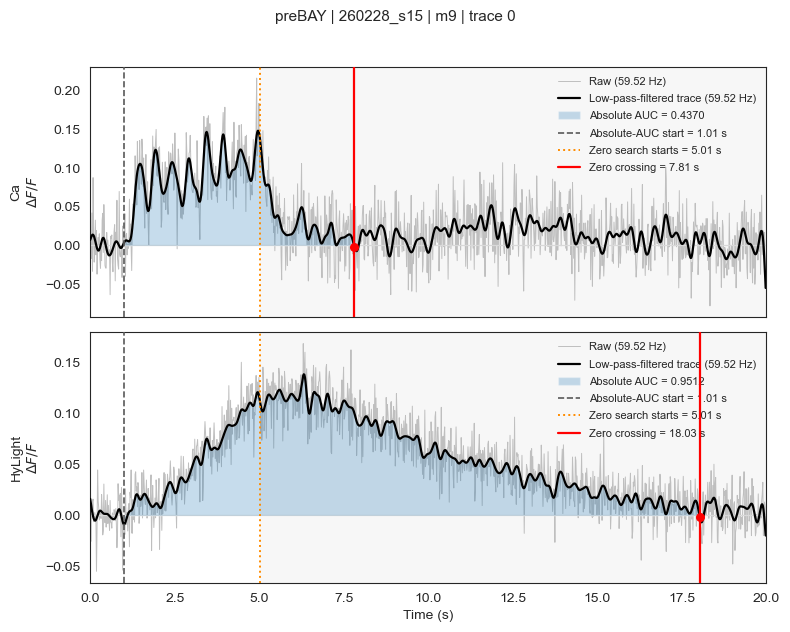

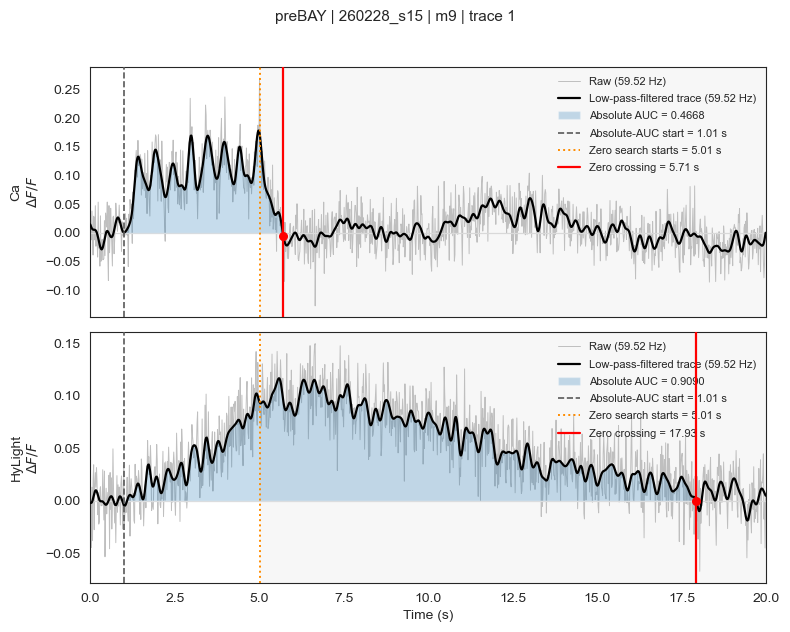

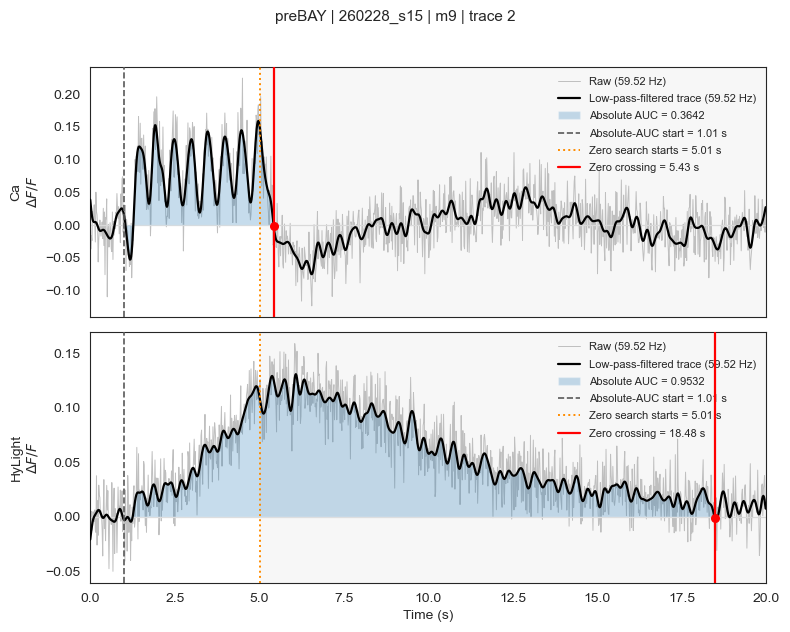

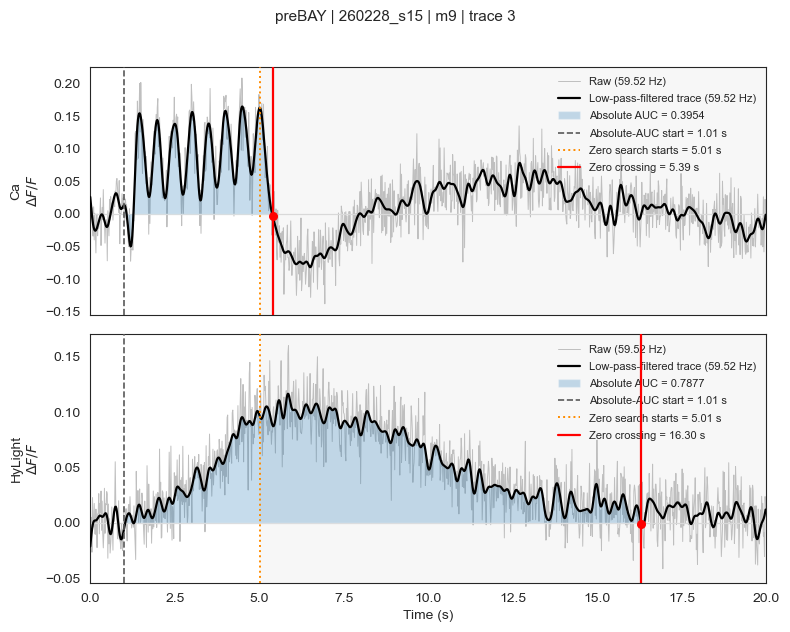

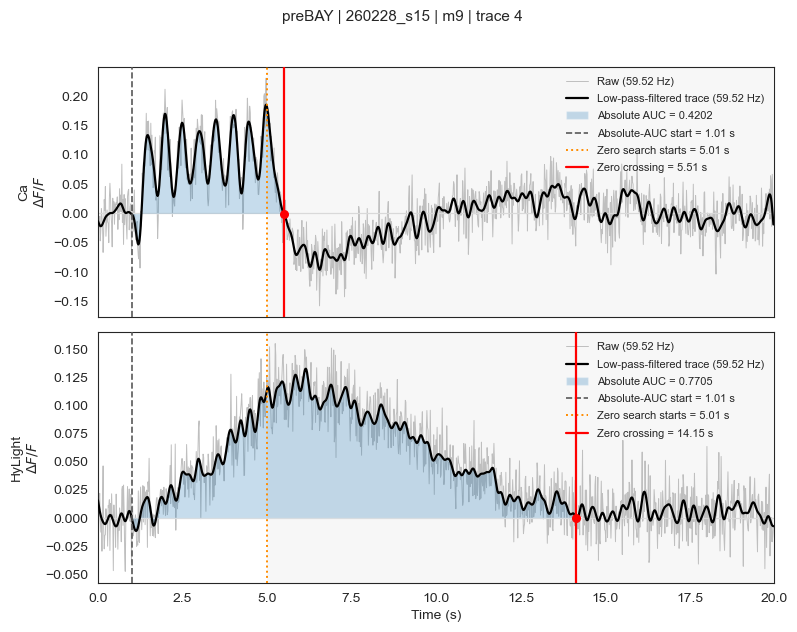

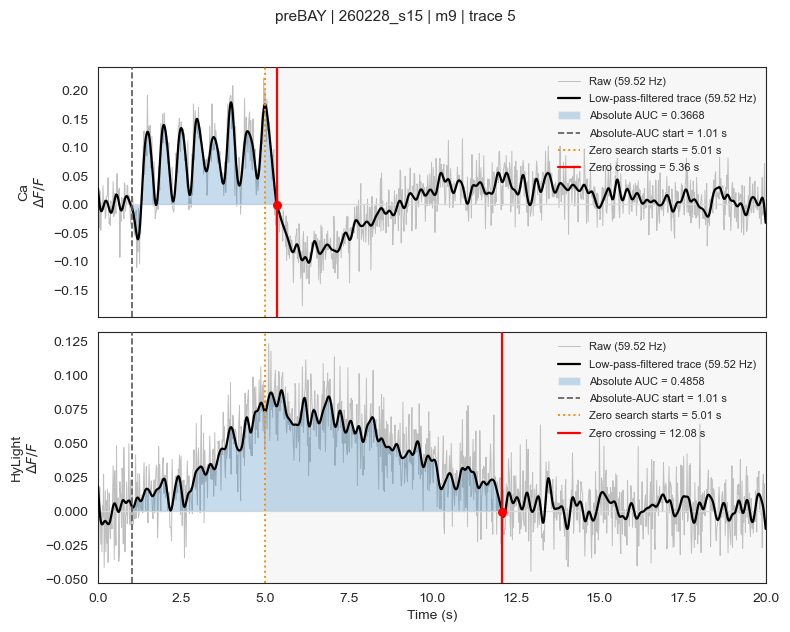

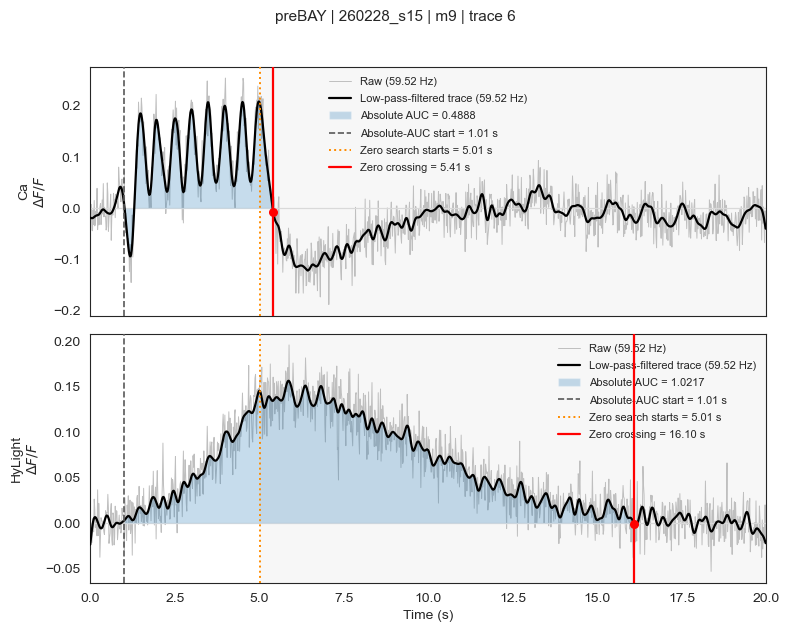


preBAY | 260302_s1 | m9 | 6 traces


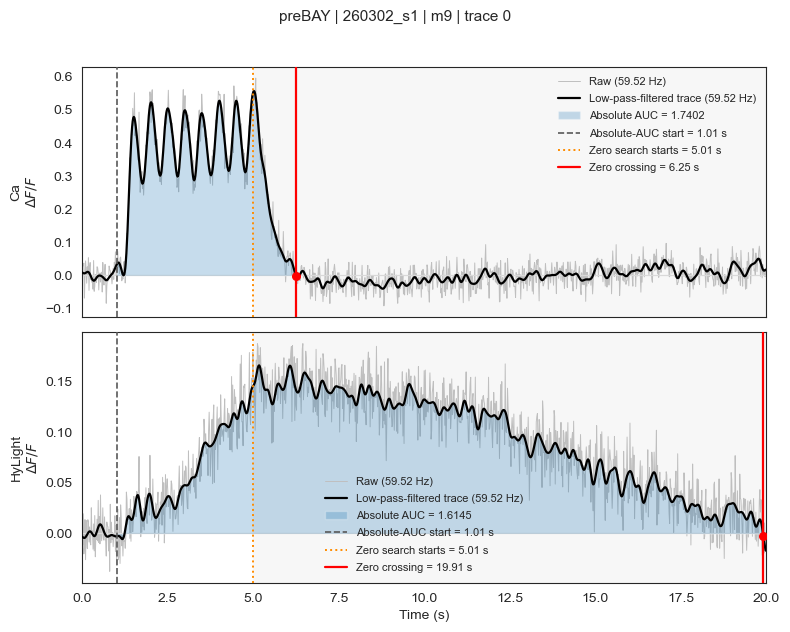

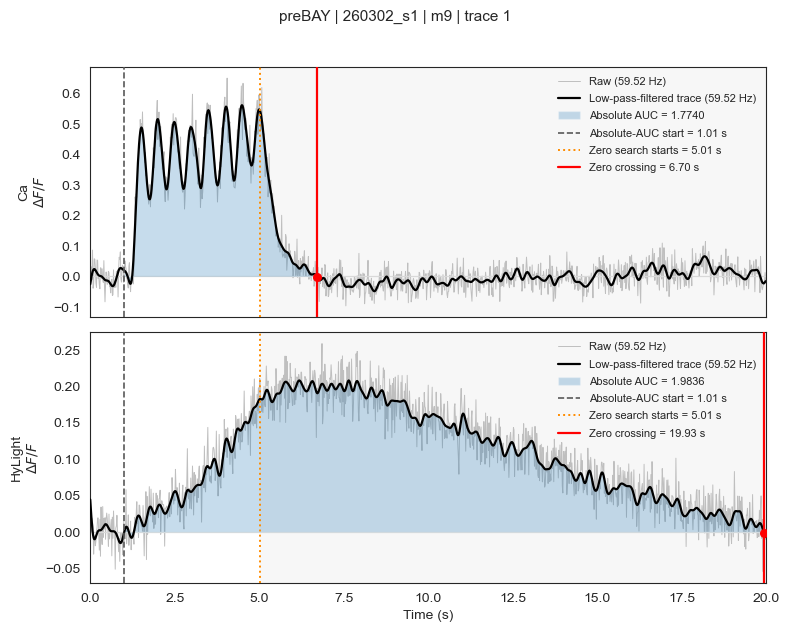

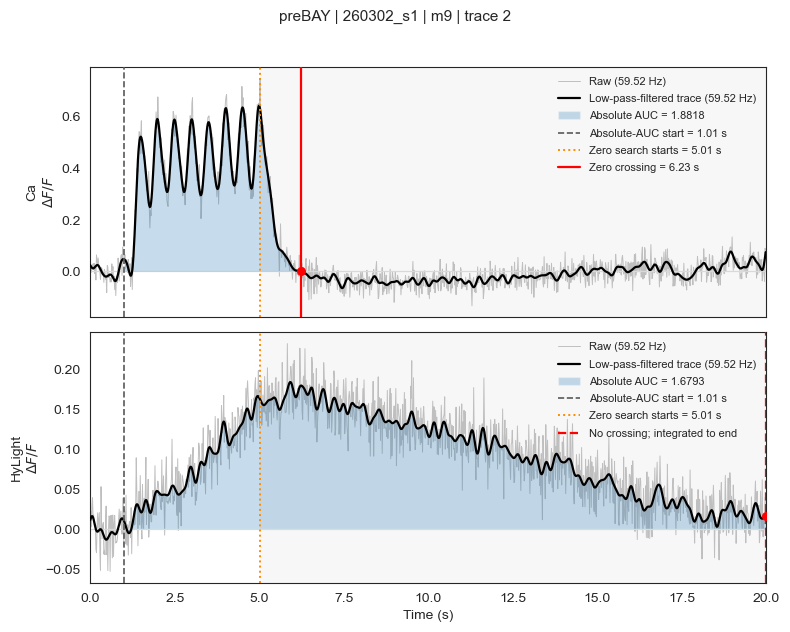

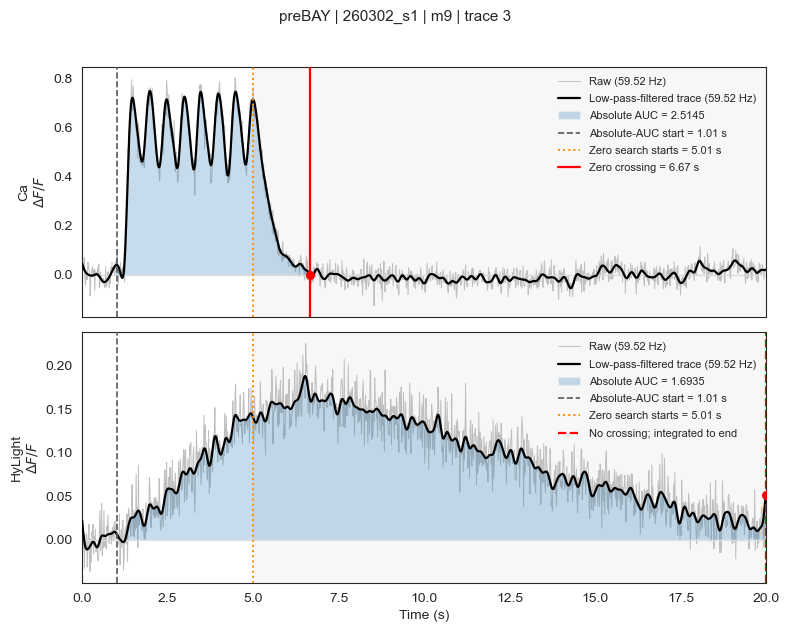

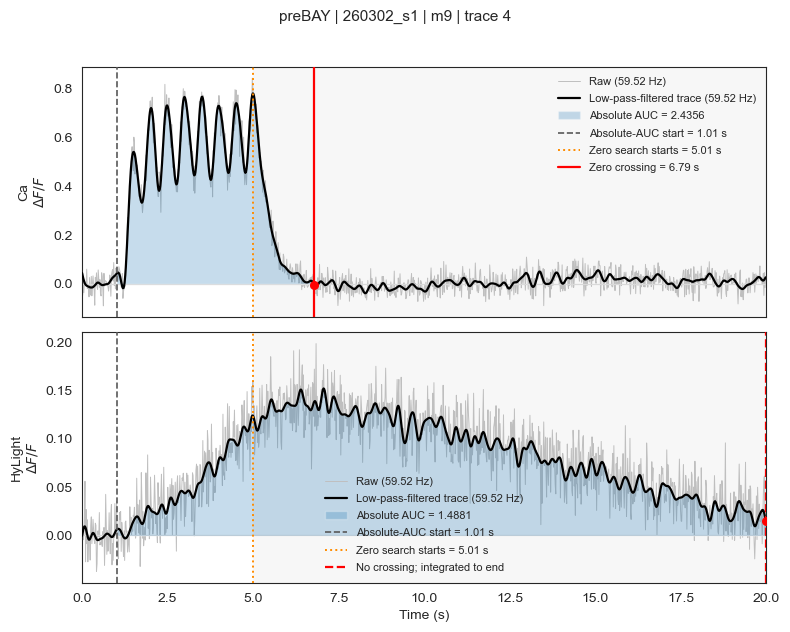

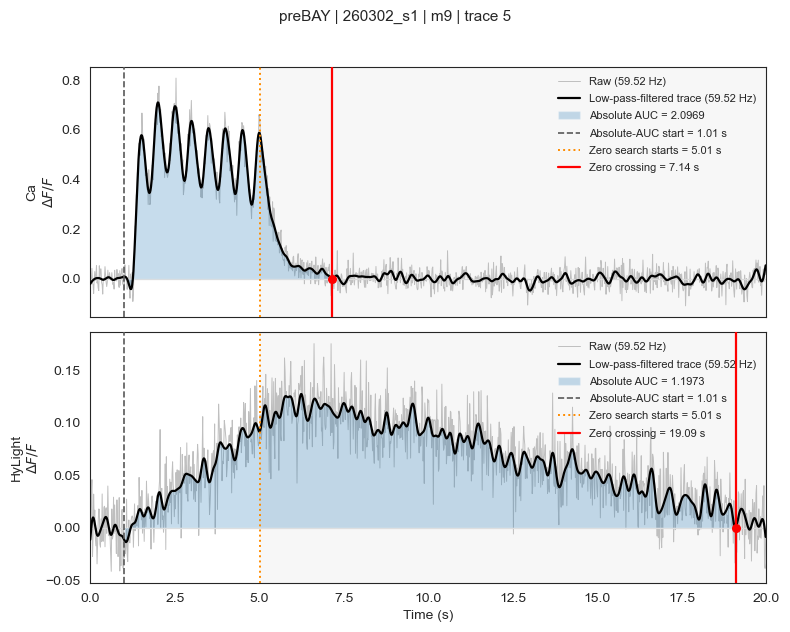


preBAY | 260302_s17 | m9 | 2 traces


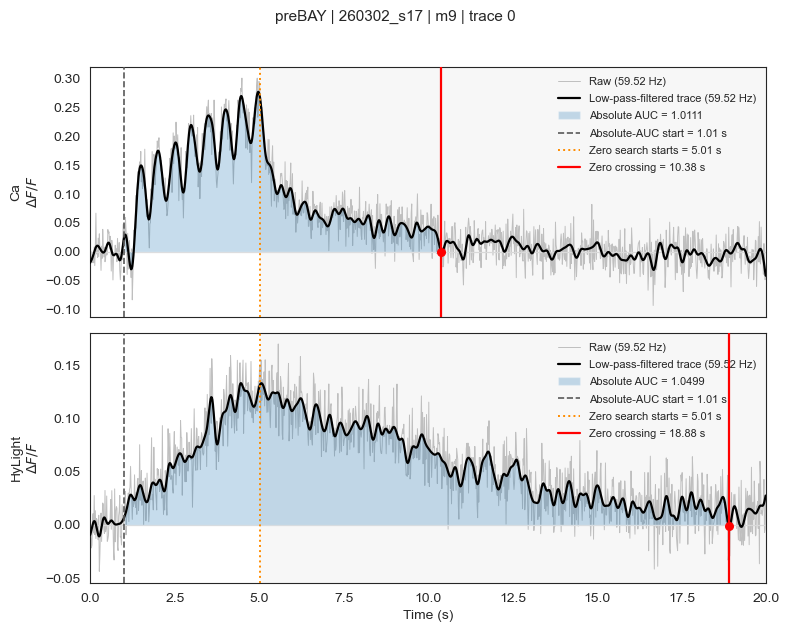

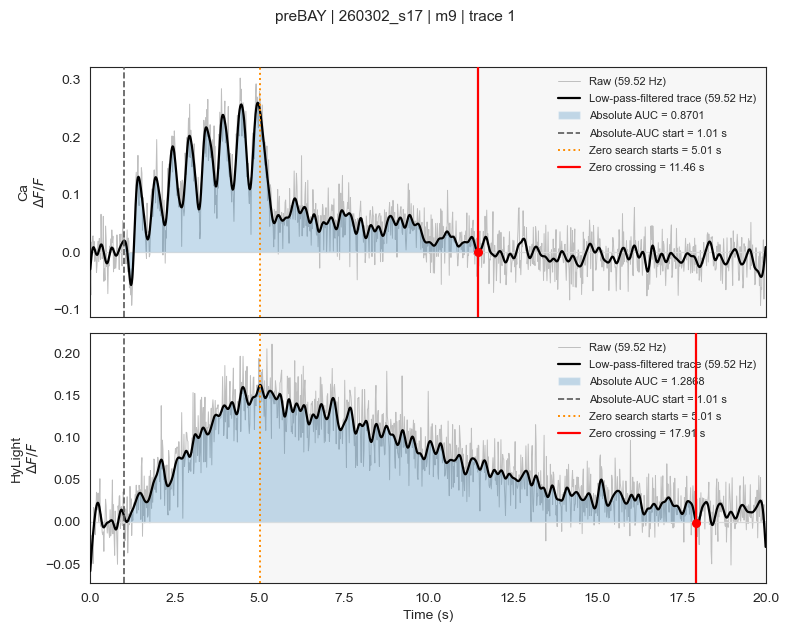


preBAY | 260302_s23 | m9 | 2 traces


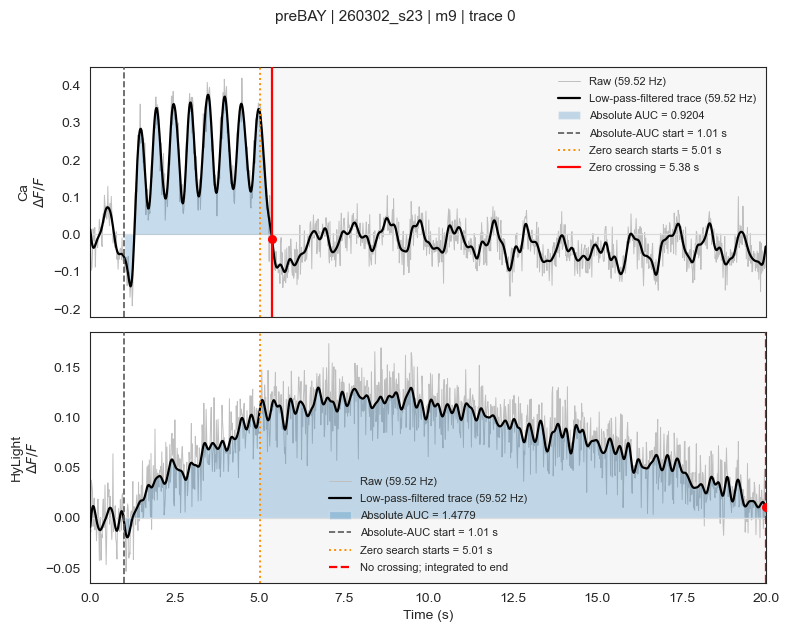

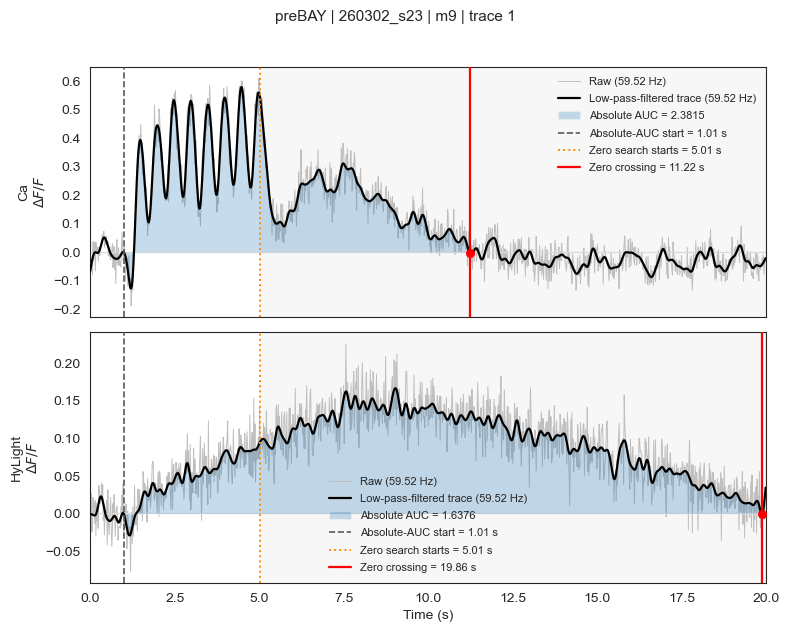


preBAY | 260302_s46 | m9 | 6 traces


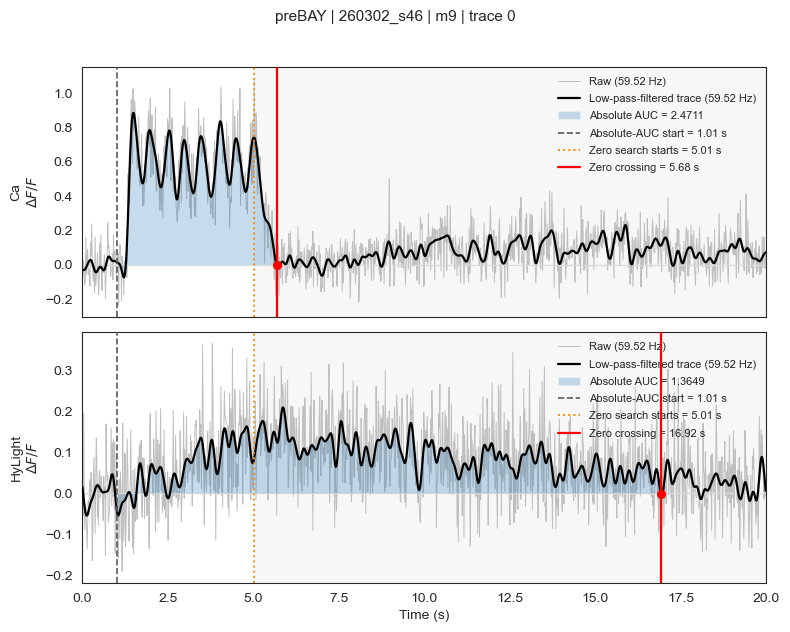

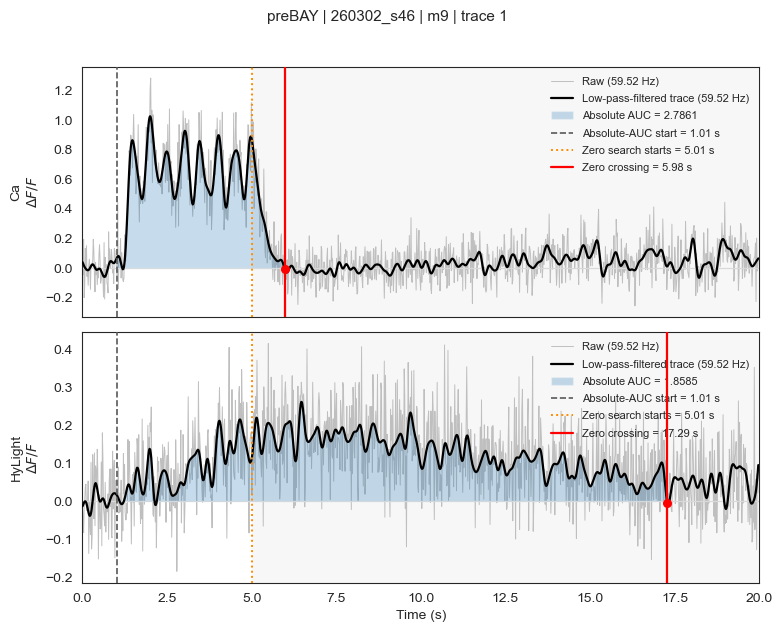

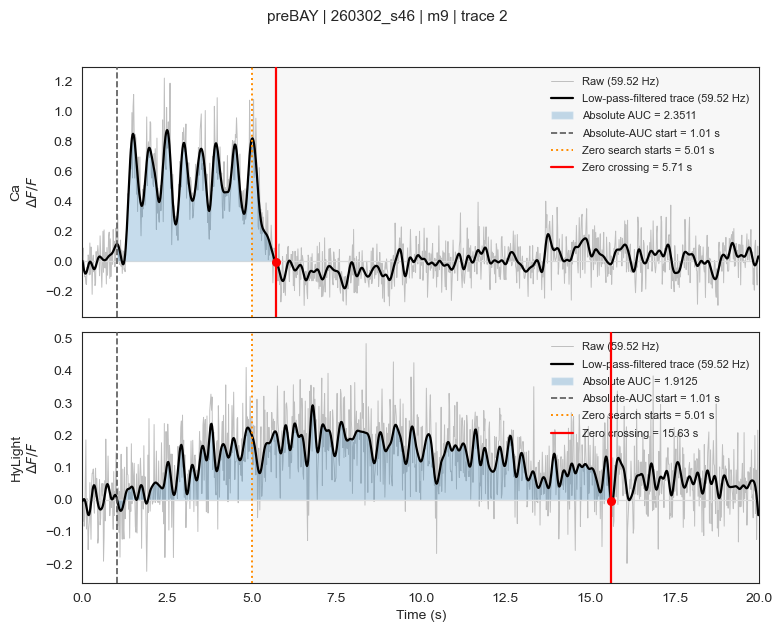


Plotted 20 neuron-level absolute-AUC checks.


In [57]:
plot_absolute_auc_sanity_checks(
    all_data,
    absolute_auc_results,

    measurements=("ca", "hylight"),

    # Use None to include all available values.
    genotypes=None,
    series=None,
    compartments=None,

    # Use None to plot every trace.
    max_plots=20,

    show_raw=True,
    show_filtered=True,
    show_zero_search_window=True,
    show_auc_start=True,
    show_zero_search_start=True,
    show_zero_crossing=True,

    xlim=(0, 20),
    ylim=None,

    verbose=True,
)

## 7. Plots
`dotplot_auc_ratio7` plots the `AUC_ratio` column. To plot the Ca or HyLight AUC alone, use the copies made in the next cell, where `AUC_ratio` is replaced by `AUC_ca` or `AUC_hylight`.

In [58]:
abs_auc_final_lowpass_df_caratio = abs_auc_final_lowpass_df.copy()
abs_auc_final_lowpass_df_caratio['AUC_ratio'] = abs_auc_final_lowpass_df_caratio['AUC_ca']

abs_auc_final_lowpass_df_HYratio = abs_auc_final_lowpass_df.copy()
abs_auc_final_lowpass_df_HYratio['AUC_ratio'] = abs_auc_final_lowpass_df_HYratio['AUC_hylight']

HyLight/Ca AUC ratio:

In [59]:
results = dotplot_auc_ratio7(
    abs_auc_final_lowpass_df,
    figsize=(9.6, 2.5),
    compartment="m9",
    control_genotypes=("control"),
    y_limits=(-0.4, 3.2),
    star_x_offset = 0.18,
    lowercase_xticklabels=True,
    italicize_xticklabels=True,
    show_tables=True,
)

results["summary"][["Genotype", "n", "mean", "sem"]]

HyLight AUC alone:

In [45]:
results = dotplot_auc_ratio7(
    abs_auc_final_lowpass_df_HYratio,
    figsize=(11, 2.5),
    compartment="m9",
    control_genotypes=("control"),
    y_limits=(-0.2, 10),
    star_x_offset = 0.18,
    lowercase_xticklabels=True,
    italicize_xticklabels=True
)

## 8. Save the AUC table (optional)

In [60]:
# Save the AUC table as a CSV file (set the path first).
output_path2 = "your/path/here/BAY_lowpass-4hz_AUC_zerocross_final.csv"

abs_auc_final_lowpass_df.to_csv(output_path2, index=False)
print("Saved to:", output_path2)

Saved to: your/path/here/BAY_lowpass-4hz_AUC_zerocross_final.csv
